In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [44]:
data = load_breast_cancer()
X = data.data
y = data.target

print(f"Dataset shape: {X.shape}")
print(f"Features count: {X.shape[1]}")
print(f"Classes: {data.target_names}")

Dataset shape: (569, 30)
Features count: 30
Classes: ['malignant' 'benign']


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape: ", X_test.shape)

Training data shape: (455, 30)
Testing data shape:  (114, 30)


In [46]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully (mean ~ 0, variance ~ 1).")

Features scaled successfully (mean ~ 0, variance ~ 1).


In [47]:
model =LogisticRegression(l1_ratio=0, C=1.0, max_iter=1000)
model.fit(X_train_scaled, y_train)

train_pred = model.predict(X_train_scaled)
test_pred = model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print(f"Unregularized Train Accuracy: {train_accuracy:.4f}")
print(f"Unregularized Test Accuracy : {test_accuracy:.4f}")

Unregularized Train Accuracy: 0.9890
Unregularized Test Accuracy : 0.9825


In [48]:
ridge_model =LogisticRegression(l1_ratio=0, C=1.0, max_iter=1000)
ridge_model.fit(X_train_scaled, y_train)

ridge_train_pred = ridge_model.predict(X_train_scaled)
ridge_test_pred = ridge_model.predict(X_test_scaled)

ridge_train_accuracy = accuracy_score(y_train, ridge_train_pred)
ridge_test_accuracy = accuracy_score(y_test, ridge_test_pred)

print(f"Ridge Train Accuracy: {ridge_train_accuracy:.4f}")
print(f"Ridge Test Accuracy : {ridge_test_accuracy:.4f}")

Ridge Train Accuracy: 0.9890
Ridge Test Accuracy : 0.9825


In [49]:
lasso_model = LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, max_iter=1000)
lasso_model.fit(X_train_scaled, y_train)

lasso_train_pred = lasso_model.predict(X_train_scaled)
lasso_test_pred = lasso_model.predict(X_test_scaled)

lasso_train_accuracy = accuracy_score(y_train, lasso_train_pred)
lasso_test_accuracy = accuracy_score(y_test, lasso_test_pred)

print(f"Lasso Train Accuracy: {lasso_train_accuracy:.4f}")
print(f"Lasso Test Accuracy : {lasso_test_accuracy:.4f}")

Lasso Train Accuracy: 0.9890
Lasso Test Accuracy : 0.9912


In [50]:
results = pd.DataFrame({
    "Model": ["Logistic Regression (None)", "Ridge (L2)", "Lasso (L1)"],
    "Training Accuracy": [
        train_accuracy,
        ridge_train_accuracy,
        lasso_train_accuracy,
    ],
    "Testing Accuracy": [
        test_accuracy,
        ridge_test_accuracy,
        lasso_test_accuracy,
    ],
})

results.round(4)

,Model,Training Accuracy,Testing Accuracy
0,Logistic Regression (None),0.989,0.9825
1,Ridge (L2),0.989,0.9825
2,Lasso (L1),0.989,0.9912


Number of features eliminated by Lasso: 13 out of 30


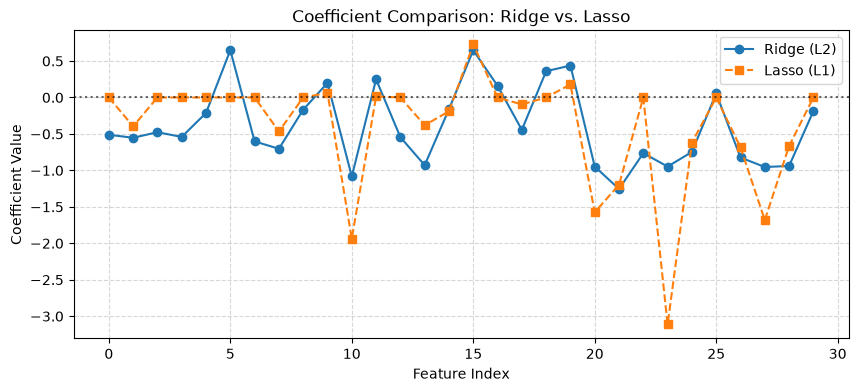

In [51]:
# Count how many coefficients Lasso set to exact 0
zero_coefs = np.sum(lasso_model.coef_ == 0)
print(
    f"Number of features eliminated by Lasso: {zero_coefs} out of"
    f" {X.shape[1]}"
)

# Plot coefficient comparisons
plt.figure(figsize=(10, 4))
plt.plot(ridge_model.coef_[0], "o-", label="Ridge (L2)")
plt.plot(lasso_model.coef_[0], "s--", label="Lasso (L1)")
plt.axhline(0, color="black", linestyle=":", alpha=0.6)
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Comparison: Ridge vs. Lasso")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()